# Accident Risk on National Highways in South Holland
**TIL6022 Python Programming Group 32 Final Report**

| **Student Name** | **Student ID** |
|------------------|----------------|
| Erdem Aydin      |   5822394     |
| Francisco de Meij|         |
| Floris Korthals Altes|   |
| Rosanna Kliffen  |         |
| Thijs de Vegt    |         |

## Introduction
Traffic accidents on national highways can cause injuries, fatalities, economic losses and disruptions to transport. Identifying sections that deserve closer safety investigation is therefore important for road authorities. However, the sections with the most recorded crashes are not necessarily the most accident-prone relative to the amount of traffic using them. A busy section may have a high crash count simply because many vehicles travel through it, whereas a quieter section may have fewer crashes but a higher rate per kilometre driven. Previous research also shows that crash frequency tends to increase with traffic volume, though not always proportionally (Høye & Hesjevoll, 2020).

This project examines national-highway carriageway sections in South Holland during 2025. Building on earlier Dutch road-safety benchmarking (Schepers et al., 2020), it distinguishes the total burden of registered crashes from exposure-adjusted rates and considers whether road and traffic characteristics help explain differences across sections. The motivation is to provide a more informative basis for identifying potentially problematic locations, without assuming that observed crash patterns alone establish their causes.

## Research Objectives

**Objective.** Identify national-highway carriageway sections in South Holland with relatively high crash frequencies in 2025 after taking traffic volume into account, and investigate traffic and carriageway characteristics associated with differences in crash frequency.

**Main research question**

> **Which highway carriageway sections in South Holland have the highest crash rates in 2025, given how busy they are, and which traffic and carriageway characteristics are associated with differences in crash frequency?**

**Sub-questions**

1. How does the ranking of carriageway sections by number of accidents differ from the ranking by risk (accidents per million vehicle-kilometres)?
2. Which carriageway and traffic characteristics are associated with higher crash frequency after controlling for traffic volume and section length?
3. Are the carriageway sections with the highest risk of injury and fatal accidents the same as those with the highest risk of all accidents?

The analysis brings together registered accidents (BRON), road identifiers (NWB) and traffic intensities (INWEVA) at carriageway-section level (`VBN_ID`). The cleaned dataset comprises 1,228 sections. Annual traffic exposure is estimated as $E_i=365\times\text{daily traffic}_i\times\text{length}_i\text{ (km)}$, with rates expressed as registered crashes per million vehicle-kilometres. These are observed rates, not direct probabilities of an individual driver's crash.


## Methods

The analysis uses the cleaned BRON and INWEVA 2025 data, with national-highway carriageway sections in South Holland as the unit of analysis. The combined dataset contains 1,228 sections, with traffic data available for 1,223 sections. The mean section length is 766 m (median 503 m), while the mean number of registered crashes is 5.94 (median 1). Among sections with traffic data, average daily traffic is approximately 22,987 vehicles (median 15,300). In total, the dataset contains 7,293 assigned crashes, including 707 injury crashes and 11 fatal crashes.

To compare sections with different traffic volumes and lengths, annual traffic exposure is estimated in vehicle-kilometres:

$$
E_i = 365\,T_i\,\frac{L_i}{1000},
$$

where $T_i$ represents average daily traffic and $L_i$ is section length in metres. Overall crash rates and injury/fatal crash rates are calculated as:

$$
R_i = \frac{C_i}{E_i}\times 10^6,
\qquad
R_i^{IF} = \frac{I_i+F_i}{E_i}\times 10^6,
$$

where $C_i$ is the total number of crashes, and $I_i$ and $F_i$ represent injury and fatal crashes, respectively. Both rates are expressed per million vehicle-kilometres. For Sub-question 2, additional explanatory variables include carriageway type, heavy-goods-vehicle (HGV) share, and night-time traffic share. HGV share is calculated from medium-heavy and heavy vehicle counts relative to total traffic, while night-time share represents the proportion of traffic occurring at night.

Each sub-question applies a different analytical approach:

| Analysis | Sample | Method |
|---|---|---|
| **SQ1: Crash counts vs. rates** | 1,228 sections for crash-count rankings; 849 sections for rate comparisons | Top-10 rankings, ranking overlap, Spearman correlation, exposure scatterplot, and pooled carriageway-type rates |
| **SQ2: Carriageway characteristics** | 1,208 sections with usable traffic and carriageway data | Negative Binomial regression controlling for traffic volume and section length, incidence-rate ratios, and robustness checks |
| **SQ3: Overall vs. injury and fatal rates** | 849 sections | Top-10 rankings, ranking overlap, Spearman correlation, and rate comparison scatterplot |

For SQ1 and SQ3, sections with fewer than 1 million annual vehicle-kilometres are excluded from rate comparisons to reduce extreme values caused by very low traffic exposure. This threshold retains 849 sections and 7,103 crashes (97.4% of all assigned crashes). Alternative thresholds of 0.5, 2, and 5 million vehicle-kilometres were also examined. SQ2 does not apply this threshold in its primary regression because traffic volume and section length are included as control variables.

Two methodological considerations should be noted. First, annual exposure is estimated by multiplying the supplied weekday traffic intensity by 365, assuming it reasonably represents daily traffic throughout the year. Second, exposure-adjusted rates describe observed accident frequency, while regression estimates identify statistical associations after controlling for selected characteristics. Neither measure independently establishes causality. All reported crash rates are standardized to per million vehicle-kilometres, accounting for differences in rate units across the original analysis outputs.


## SQ1: Crash Counts versus Exposure-Adjusted Rates
We ranked sections by the total number of recorded crashes and, separately, by crashes per million vehicle-kilometres. The rate comparison was limited to sections with at least 1 million annual vehicle-kilometres to reduce extreme values caused by very small denominators (849 eligible sections). The count ranking uses all 1,228 sections.

**Table 1.** Ten sections with the highest annual crash totals. The road descriptions reproduce abbreviated labels in the team's saved output.

| Carriageway section | Length (m) | Vehicles/day | Crashes | Crashes / million vehicle-km |
| --- | --- | --- | --- | --- |
| A16 Li (HR) Knooppunt IJsselmondse Plein - Van... | 6,296 | 48,300 | 159 | 1.43 |
| A4 Re (HR) Leiden | 4,807 | 49,600 | 156 | 1.79 |
| A4 Li (HR) Knooppunt Prins Clausplein - Kp.pr.... | 2,371 | 54,700 | 107 | 2.26 |
| A20 Li (HR) KP TERBREGSEPLEIN - Rotterdam-Croo... | 2,339 | 66,200 | 94 | 1.66 |
| A16 Re (HR) Van Brienenoordbrug - Knooppunt IJ... | 5,059 | 52,700 | 92 | 0.95 |
| A15 Li (HR) Portlandsebrug | 4,431 | 45,400 | 78 | 1.06 |
| A4 Li (HR) Kp.pr.clausplein - Leidschendam-Voo... | 5,894 | 87,800 | 76 | 0.4 |
| A4 Li (HR) Kp.kethelplein - Delft | 5,381 | 53,500 | 75 | 0.71 |
| A20 Re (HR) Pr.alexander - Nieuwerkerk A/d Ijssel | 4,033 | 50,300 | 74 | 1 |
| A20 Li (HR) Rotterdam-Pr.alexander - KP TERBRE... | 1,032 | 70,800 | 73 | 2.74 |

**Table 2.** Ten highest exposure-adjusted crash rates (at least 1 million annual vehicle-kilometres).

| Carriageway section | Length (m) | Vehicles/day | Crashes | Crashes / million vehicle-km |
| --- | --- | --- | --- | --- |
| A20 a (AFR) Rotterdam-Noord | 400 | 7,700 | 10 | 8.9 |
| A4 b (OPR) Vlaardingen-Oost | 287 | 10,300 | 9 | 8.34 |
| A20 d (OPR) Rotterdam-Schiebroek | 415 | 12,200 | 11 | 5.95 |
| A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl... | 400 | 7,000 | 6 | 5.87 |
| A4 a (AFR) Vlaardingen-Oost | 380 | 8,500 | 6 | 5.09 |
| A15 a (AFR) Rotterdam-Ijsselmonde | 404 | 14,200 | 10 | 4.78 |
| A4 c (AFR) Leiden | 603 | 6,200 | 6 | 4.4 |
| A15 Re (HR) Rotterdam - oostvoorne | 731 | 13,700 | 15 | 4.1 |
| A29 Re (HR) Knooppunt Vaanplein | 627 | 7,800 | 7 | 3.92 |
| A20 b (OPR) Rotterdam-Noord | 251 | 16,800 | 6 | 3.9 |

None of the sections in these two top-10 lists overlap. Sections with the highest counts are long, busy main carriageways (73–159 crashes), whereas the highest observed rates mostly occur on shorter on- and off-ramps (approximately 4–9 crashes per million vehicle-kilometres). Across eligible sections, Spearman's rank correlation between counts and rates is $\rho=0.71$; among sections with at least one crash, it decreases to $\rho=0.40$. These are correlation coefficients, not p-values.

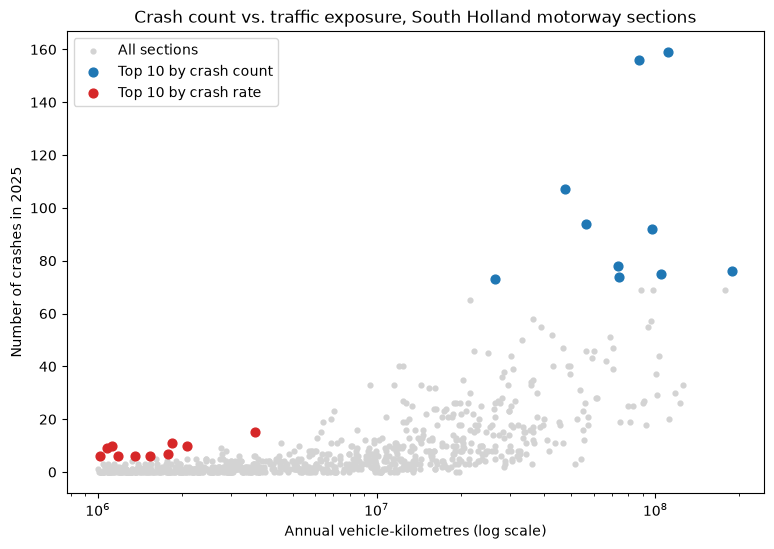

*Figure 1. Recorded crash counts versus annual traffic exposure, highlighting sections with high counts and high rates (source: SQ1 notebook).*

Pooling crashes and exposure by carriageway type provides a less section-specific comparison: off-ramps 1.00, on-ramps 0.93, and main carriageways 0.65 crashes per million vehicle-kilometres. Main carriageways nonetheless account for the large majority of recorded accidents (6,324 of 7,293). These pooled comparisons are descriptive, not adjusted for other characteristics.

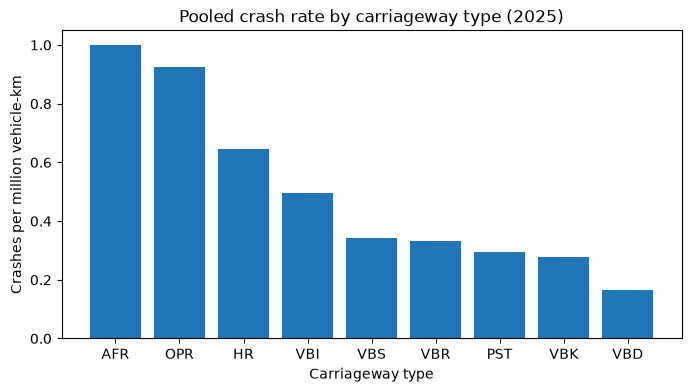

*Figure 2. Pooled crash rates per million vehicle-kilometres by carriageway type (source: SQ1 notebook).*

## SQ2: Carriageway and Traffic Characteristics
A Negative Binomial regression was fitted to total crash counts, with log traffic intensity and log section length as controls, alongside carriageway type, heavy-goods-vehicle (HGV) share and night-traffic share. The sample includes 1,208 sections and 7,282 crashes. Crash-count variance (**174.9**) greatly exceeds the mean (**6.0**); the Negative Binomial fit is substantially better than Poisson (AIC **4,979.1** versus **7,255.6**). Results for characteristics are expressed as incidence rate ratios (IRRs): an IRR below 1 indicates fewer expected crashes conditional on the included controls.

**Table 3.** Negative Binomial model results (reference type: main carriageway). Share effects correspond to a one-percentage-point increase.

| Predictor | IRR | 95% CI | p-value |
| --- | --- | --- | --- |
| Connector (vs main carriageway) | 0.331 | 0.276–0.398 | <0.001 |
| On-ramp (vs main carriageway) | 0.811 | 0.615–1.069 | 0.137 |
| Off-ramp (vs main carriageway) | 0.84 | 0.636–1.108 | 0.217 |
| HGV share (+1 percentage point) | 0.999 | 0.989–1.009 | 0.809 |
| Night-traffic share (+1 percentage point) | 1.026 | 1.001–1.053 | 0.043 |

Traffic and length are positively but less than proportionally related to crash counts (estimated log coefficients **0.82** and **0.69**, respectively). Connectors have about 67% fewer expected crashes than comparable main carriageways (IRR **0.33**), while on- and off-ramp differences are not statistically significant. HGV share is not significant; night-traffic share has a small positive association (IRR **1.026**, $p=0.043$), whose magnitude varies across robustness samples. Adding road and traffic characteristics improves model fit beyond traffic and length alone (likelihood-ratio statistic **160.7**, $p<0.001$).

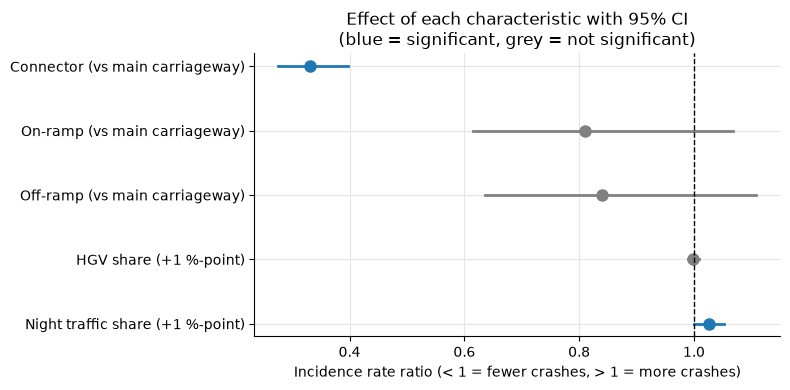

*Figure 3. Incidence rate ratios with 95% confidence intervals for tested road and traffic characteristics (source: SQ2 notebook).*

For an illustrative section with fixed median traffic (15,350 vehicles/day), length (508 m) and traffic shares, the model predicts about 3.13 crashes on a main carriageway and **1.04** on a connector; predictions for on- and off-ramps are **2.54** and **2.63**, respectively. The latter contrasts are not statistically significant in the main regression.

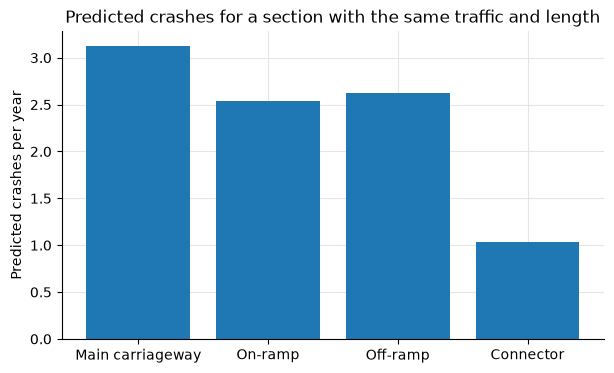

*Figure 4. Predicted annual crashes for otherwise comparable carriageway types (source: SQ2 notebook).*

As a robustness check, connectors remain significantly below main carriageways when excluding records labelled `correctie` and when restricting the sample to sections with at least 1 million annual vehicle-kilometres (connector IRRs **0.26** and **0.38**, respectively). Ramp and HGV effects remain statistically unclear; night-share estimates are positive but vary in size across samples. These associations do not establish causality.

## SQ3: Overall versus Injury and Fatal Crash Risk
Using the same 849 exposure-eligible sections as SQ1, we compared rankings based on all crashes with those based only on injury and fatal crashes, both per million vehicle-kilometres.

**Table 4.** Ten sections with the highest injury/fatal crash rates in the team's saved results.

| Carriageway section | Total crashes | Injury/fatal crashes | All crashes / M vkm | Injury/fatal / M vkm |
| --- | --- | --- | --- | --- |
| A4 c (AFR) Leiden | 6 | 2 | 4.397 | 1.466 |
| A20 b (OPR) Rotterdam-Noord | 6 | 2 | 3.898 | 1.299 |
| A29 Re (HR) Knooppunt Vaanplein | 7 | 2 | 3.921 | 1.12 |
| A20 d (OPR) Rotterdam-Schiebroek | 11 | 2 | 5.952 | 1.082 |
| A4 m (VBR) ZOETERWOUDE | 4 | 3 | 1.331 | 0.998 |
| A20 c (AFR) Knooppunt Kleinpolderplein - Kp.kl... | 6 | 1 | 5.871 | 0.978 |
| A4 b (OPR) Vlaardingen-Oost | 9 | 1 | 8.341 | 0.927 |
| A20 a (AFR) Rotterdam-Noord | 10 | 1 | 8.895 | 0.89 |
| A15 d (OPR) Alblasserdam | 2 | 1 | 1.619 | 0.81 |
| A15 b (OPR) Rotterdam-Ijsselmonde | 4 | 1 | 3.015 | 0.754 |

Seven sections appear in both top-10 rate rankings. The two rates have a moderate rank correlation ($\rho=0.46$ across eligible sections; $\rho=0.63$ among the 281 sections with an injury/fatal crash). Important exceptions remain: the A4 connector at Zoeterwoude ranks 111th for overall crash rate but 5th for injury/fatal rate, while the A15 on-ramp at Alblasserdam moves from 71st to 9th. This means serious-crash analysis can reveal locations overlooked by an all-crash ranking, although rates based on one or two severe crashes are uncertain.

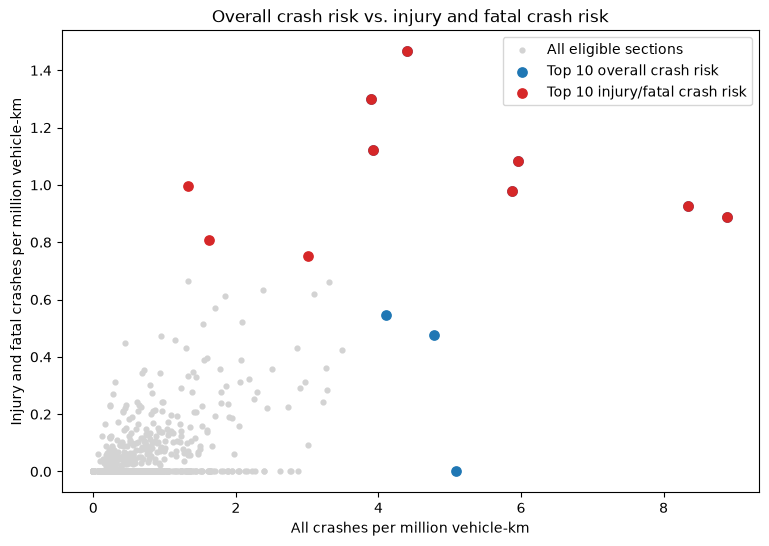

*Figure 5. Overall versus injury/fatal crash rates across eligible sections.*

## Discussion
The results demonstrate that accident burden and exposure-adjusted accident rates measure different aspects of road safety. SQ1 identifies no overlap between the ten highest-count and ten highest-rate sections. Busy main carriageways produce many accidents, while short ramps often show higher rates relative to estimated vehicle-kilometres. Neither measure should be interpreted as a complete ranking of underlying danger: high counts matter for potential total crash reduction, whereas high rates signal locations that may merit closer inspection.

The descriptive ramp pattern should be distinguished from the regression findings. SQ2 finds no statistically significant independent on-/off-ramp difference once traffic volume, length and other recorded characteristics are included, even though their pooled rates are higher. This is consistent with the model's estimated sub-proportional relationships between crash counts and traffic/length. Connectors have significantly lower adjusted crash counts, whereas the HGV share is not significant and the night-share association is comparatively small and sensitive to the sample. SQ3 adds an important distinction: most high-severity-rate hotspots overlap with high overall-rate hotspots, but several individual sections move sharply in ranking. Therefore, investigating only total counts or overall rates could overlook locations with disproportionate injury/fatal outcomes.

The conclusions are constrained by one year of registered accidents, incomplete reporting, uncertain rates where only a few severe crashes occurred, and exclusions of ambiguous junction accidents or sections with insufficient exposure. The annual exposure calculation multiplies weekday-labelled INWEVA intensity by 365, which may not fully reflect weekday–weekend differences. Results are observational associations, not causal effects. Future work could verify annual traffic factors, combine multiple years, quantify uncertainty in hotspot rankings, and assess local road geometry or safety measures before selecting interventions.

## Conclusion
The analyses show that raw crash counts and exposure-adjusted rates lead to different assessments of national-highway safety in South Holland in 2025. The highest observed crash rates occur on sections such as A20 a (AFR) Rotterdam-Noord (8.90), A4 b (OPR) Vlaardingen-Oost (8.34) and A20 d (OPR) Rotterdam-Schiebroek (5.95 crashes per million vehicle-kilometres). None of the ten highest-rate sections is among the ten sections with the most crashes. Thus, busy sections with large accident totals and sections with disproportionately high observed rates are not necessarily the same places.

The regression results add context to these descriptive comparisons. After accounting for traffic volume, section length and other included characteristics, connectors have lower expected crash counts than main carriageways, whereas on-/off-ramp and heavy-goods-vehicle-share effects are not statistically significant. In the severity comparison, seven of the ten highest injury/fatal-rate sections also appear among the highest overall-rate sections, but differences in individual rankings show why serious outcomes should be examined separately.

Overall, the findings suggest that Rijkswaterstaat and other road authorities should consider crash totals, exposure-adjusted rates and injury/fatal rates together when deciding which sections merit further investigation. These results highlight potential priorities rather than proving that particular road features cause crashes or identifying definitive engineering solutions. Further assessment using multiple years of observations and additional local safety information would strengthen decisions about targeted improvements.

## Contribution Statement

| Student Name | Contribution |
| --- | --- |
| Thijs de Vegt |  |
| Francisco de Meij |  |
| Floris Korthals Altes |  |
| Rosanna Kliffen |  |
| Erdem Aydin |  |

## References
Høye, A. K., & Hesjevoll, I. S. (2020). Traffic volume and crashes and how crash and road characteristics affect their relationship: A meta-analysis. *Accident Analysis & Prevention, 145*, 105668. https://www.sciencedirect.com/science/article/pii/S0001457520307934


Schepers, J. P., van Petegem, J. W. H., Bijleveld, F. D., & Louwerse, W. J. R. (2020). *Dodelijke ongevallen op rijkswegen in Zuid-Nederland: Benchmarking verkeersveiligheid* (R-2020-8). SWOV. https://zoek.officielebekendmakingen.nl/blg-981136.pdf


Rijkswaterstaat. (2025). *BRON — Bestand geRegistreerde Ongevallen Nederland* [Open data]. https://data.overheid.nl/dataset/9841-verkeersongevallen---bestand-geregistreerde-ongevallen-nederland


Rijkswaterstaat. (2025). *INWEVA — Intensiteiten op Wegvakken* [Open data]. https://data.overheid.nl/dataset/84461-intensiteit-wegvakken--inweva-#panel-resources

## AI Statement
AI was used in this assignment to...